# Análise de Dados - Colônia Aurora Siger
### Fase 3 · Capítulo 1 - *A Aurora Estabelece os Primeiros Sistemas da Colônia*

Este notebook cobre a **análise dos dados** da atividade. Ele **não gera dados**: consome o módulo `gerar_dados.py` e trabalha apenas com o que ele devolve.

| Requisito do capítulo | Onde é atendido |
| --- | --- |
| Organizar os dados (listas, chave-valor, hierarquia) | Seção 2 |
| Analisar o uso de energia (geração x consumo x reserva) | Seção 3 |
| Tomar decisões automaticamente (regras e prioridades) | Seção 4 |
| Prever comportamentos com regressão linear | Seção 5 |
| Resumo dos resultados | Seção 6 |

As regras de decisão e a regressão usam **apenas Python puro** (sem bibliotecas avançadas); `pandas` e `matplotlib` aparecem só para tabular e visualizar os dados.

## 1. Consumo do módulo `gerar_dados`

O módulo gera 24 horas de clima (vento, irradiância, temperatura), geração (solar e eólica), consumo dos quatro módulos da colônia e os parâmetros da bateria.

Como a geração usa `np.random`, fixamos a semente para que a análise seja reproduzível.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
import sys

# Localiza utils tanto a partir do notebook quanto da raiz do repositorio.
for base in (Path.cwd(), *Path.cwd().parents):
    candidatos = (base / "utils", base / "1CCOMP" / "FASE3-ATIVIDADE" / "utils")
    pasta_utils = next((p for p in candidatos if (p / "gerar_dados.py").is_file()), None)
    if pasta_utils is not None:
        break
else:
    raise FileNotFoundError("Nao foi encontrado utils/gerar_dados.py a partir da pasta atual.")

if str(pasta_utils) not in sys.path:
    sys.path.insert(0, str(pasta_utils))

import gerar_dados as gd

np.random.seed(42)

dados = gd.gerar_dados()
historico = dados["historico"]

print("Chaves do dicionário principal:", list(dados.keys()))
print("Registros no histórico:", len(historico))
print("Bateria:", dados["bateria"])

Chaves do dicionário principal: ['estrutura', 'bateria', 'historico']
Registros no histórico: 24
Bateria: {'capacidade_kwh': 200, 'reserva_inicial_kwh': 100}


## 2. Organização dos dados


### 2.1 Estrutura hierárquica

`dados["estrutura"]` organiza a colônia em sistema energético (geração → solar/eólica, armazenamento → bateria) e consumidores (essenciais e não essenciais). A função abaixo percorre a árvore em qualquer nível.

In [5]:
def mostrar_hierarquia(estrutura, nivel=0):
    # Percorre a estrutura hierárquica da colônia (dicionários e listas aninhados).
    for chave, valor in estrutura.items():
        print("  " * nivel + "- " + chave)
        if isinstance(valor, dict):
            mostrar_hierarquia(valor, nivel + 1)
        else:
            for item in valor:
                print("  " * (nivel + 1) + "• " + item)


mostrar_hierarquia(dados["estrutura"])

- energia
  - geracao
    • solar
    • eolica
  - armazenamento
    • bateria
- consumidores
  - essenciais
    • suporte_vida
    • comunicacao
  - nao_essenciais
    • laboratorio
    • lazer


### 2.2 Registro chave-valor

Cada hora do histórico é um dicionário: acessar um campo é uma busca direta pela chave, sem percorrer listas.

In [6]:
registro = historico[12]

print("Registro da hora", registro["hora"])
for grupo in ("clima", "geracao", "consumo"):
    print("\n[" + grupo + "]")
    for campo, valor in registro[grupo].items():
        print(f"  {campo}: {valor}")

Registro da hora 12

[clima]
  vento_ms: 6
  irradiancia_wm2: 550
  temperatura_c: -35

[geracao]
  solar_kwh: 22.0
  eolica_kwh: 13.0
  total_kwh: 35.0

[consumo]
  suporte_vida_kwh: 18
  comunicacao_kwh: 5
  laboratorio_kwh: 6
  lazer_kwh: 3
  total_kwh: 32


### 2.3 Listas: o histórico vira séries paralelas

Transformar a lista de dicionários em listas paralelas é o que permite comparar variáveis e alimentar a regressão.

In [7]:
def extrair_series(historico):
    # Converte o histórico (lista de dicionários) em listas paralelas.
    series = {
        "hora": [], "vento_ms": [], "irradiancia_wm2": [], "temperatura_c": [],
        "solar_kwh": [], "eolica_kwh": [], "geracao_kwh": [], "consumo_kwh": [],
    }
    for registro in historico:
        series["hora"].append(registro["hora"])
        series["vento_ms"].append(registro["clima"]["vento_ms"])
        series["irradiancia_wm2"].append(registro["clima"]["irradiancia_wm2"])
        series["temperatura_c"].append(registro["clima"]["temperatura_c"])
        series["solar_kwh"].append(registro["geracao"]["solar_kwh"])
        series["eolica_kwh"].append(registro["geracao"]["eolica_kwh"])
        series["geracao_kwh"].append(registro["geracao"]["total_kwh"])
        series["consumo_kwh"].append(registro["consumo"]["total_kwh"])
    return series


series = extrair_series(historico)
df = pd.DataFrame(series)

print(df.to_string(index=False, float_format=lambda v: f"{v:7.1f}"))

 hora  vento_ms  irradiancia_wm2  temperatura_c  solar_kwh  eolica_kwh  geracao_kwh  consumo_kwh
    0         8                0            -32        0.0        20.0         20.0           31
    1        10                0            -42        0.0        26.0         26.0           41
    2        12                0            -56        0.0        30.0         30.0           30
    3         6                0            -28        0.0        15.0         15.0           41
    4         4                0            -63        0.0         8.0          8.0           31
    5         5                0            -50        0.0        12.5         12.5           40
    6         7               50            -32        2.0        19.5         21.5           31
    7         9              100            -52        4.0        22.5         26.5           32
    8        11              200            -48        8.0        25.5         33.5           36
    9        13              3

## 3. Análise do uso de energia

### 3.1 Balanço do dia

In [8]:
geracao_total = sum(series["geracao_kwh"])
consumo_total = sum(series["consumo_kwh"])
saldo = geracao_total - consumo_total

print(f"Geração solar no dia:    {sum(series['solar_kwh']):7.1f} kWh")
print(f"Geração eólica no dia:   {sum(series['eolica_kwh']):7.1f} kWh")
print(f"Geração total no dia:    {geracao_total:7.1f} kWh")
print(f"Consumo total no dia:    {consumo_total:7.1f} kWh")
print(f"Saldo (geração-consumo): {saldo:+7.1f} kWh")
print()
if consumo_total > geracao_total:
    print(f"RESULTADO: a colônia fecha o dia em déficit de {abs(saldo):.1f} kWh.")
else:
    print(f"RESULTADO: a colônia fecha o dia com excedente de {saldo:.1f} kWh.")

Geração solar no dia:      146.0 kWh
Geração eólica no dia:     475.0 kWh
Geração total no dia:      621.0 kWh
Consumo total no dia:      879.0 kWh
Saldo (geração-consumo):  -258.0 kWh

RESULTADO: a colônia fecha o dia em déficit de 258.0 kWh.


### 3.2 Classificação hora a hora

Regra simples pedida no capítulo: se o consumo supera a geração há **risco**; se a geração supera o consumo há **excedente** que pode ser armazenado.

In [9]:
def classificar_balanco(geracao, consumo):
    # Compara geração e consumo e devolve a situação da hora.
    if consumo > geracao:
        return "RISCO: consumo maior que geração"
    elif geracao > consumo:
        return "SUGESTÃO: armazenar energia excedente"
    return "EQUILÍBRIO: geração igual ao consumo"


df["situacao"] = [
    classificar_balanco(geracao, consumo)
    for geracao, consumo in zip(df["geracao_kwh"], df["consumo_kwh"])
]

print("Situação das 24 horas:")
for situacao, quantidade in df["situacao"].value_counts().items():
    print(f"  {quantidade:2d} h  {situacao}")

Situação das 24 horas:
  19 h  RISCO: consumo maior que geração
   3 h  SUGESTÃO: armazenar energia excedente
   2 h  EQUILÍBRIO: geração igual ao consumo


### 3.3 Reserva da bateria

A bateria começa com 100 kWh (capacidade 200 kWh). A simulação descarrega quando o consumo é maior que a geração, carrega com o excedente e registra o que não pôde ser atendido ou armazenado.

In [10]:
def simular_bateria(series, capacidade_kwh, reserva_inicial_kwh):
    # Percorre as 24 horas atualizando a reserva da bateria.
    reserva = reserva_inicial_kwh
    simulacao = []

    for hora, geracao, consumo in zip(
        series["hora"], series["geracao_kwh"], series["consumo_kwh"]
    ):
        saldo = geracao - consumo
        excedente_perdido = 0.0
        deficit_nao_atendido = 0.0

        if saldo >= 0:
            nova_reserva = min(capacidade_kwh, reserva + saldo)
            excedente_perdido = (reserva + saldo) - nova_reserva
            reserva = nova_reserva
        else:
            deficit_nao_atendido = abs(min(0.0, reserva + saldo))
            reserva = max(0.0, reserva + saldo)

        simulacao.append({
            "hora": hora,
            "reserva_kwh": reserva,
            "excedente_perdido_kwh": excedente_perdido,
            "deficit_nao_atendido_kwh": deficit_nao_atendido,
        })

    return simulacao


bateria = dados["bateria"]
simulacao = simular_bateria(
    series, bateria["capacidade_kwh"], bateria["reserva_inicial_kwh"]
)
df_bateria = pd.DataFrame(simulacao)

print(f"Reserva inicial: {bateria['reserva_inicial_kwh']:.0f} kWh | Capacidade: {bateria['capacidade_kwh']:.0f} kWh")
print(f"Reserva mínima no dia:   {df_bateria['reserva_kwh'].min():6.1f} kWh")
print(f"Reserva final do dia:    {df_bateria['reserva_kwh'].iloc[-1]:6.1f} kWh")
print(f"Horas com bateria vazia: {int((df_bateria['reserva_kwh'] == 0).sum()):d}")
print(f"Excedente não armazenado: {df_bateria['excedente_perdido_kwh'].sum():6.1f} kWh")
print(f"Consumo não atendido:     {df_bateria['deficit_nao_atendido_kwh'].sum():6.1f} kWh")

Reserva inicial: 100 kWh | Capacidade: 200 kWh
Reserva mínima no dia:      0.0 kWh
Reserva final do dia:       0.0 kWh
Horas com bateria vazia: 14
Excedente não armazenado:    0.0 kWh
Consumo não atendido:      158.0 kWh


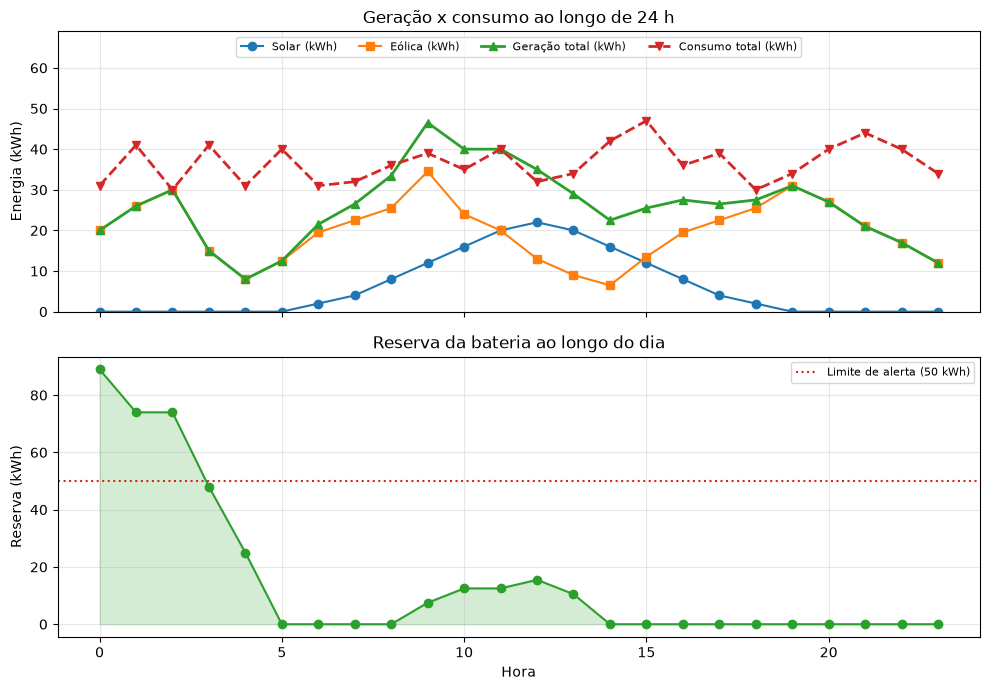

In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax1.plot(df["hora"], df["solar_kwh"], marker="o", label="Solar (kWh)")
ax1.plot(df["hora"], df["eolica_kwh"], marker="s", label="Eólica (kWh)")
ax1.plot(df["hora"], df["geracao_kwh"], marker="^", linewidth=2, label="Geração total (kWh)")
ax1.plot(df["hora"], df["consumo_kwh"], marker="v", linestyle="--", linewidth=2, label="Consumo total (kWh)")
ax1.set_ylabel("Energia (kWh)")
ax1.set_title("Geração x consumo ao longo de 24 h")
ax1.set_ylim(0, max(max(df["consumo_kwh"]), max(df["geracao_kwh"])) + 22)
ax1.legend(fontsize=8, ncol=4, loc="upper center")
ax1.grid(alpha=0.3)

ax2.plot(df_bateria["hora"], df_bateria["reserva_kwh"], marker="o", color="tab:green")
ax2.fill_between(df_bateria["hora"], df_bateria["reserva_kwh"], color="tab:green", alpha=0.2)
ax2.axhline(50, color="tab:red", linestyle=":", label="Limite de alerta (50 kWh)")
ax2.set_xlabel("Hora")
ax2.set_ylabel("Reserva (kWh)")
ax2.set_title("Reserva da bateria ao longo do dia")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Regras de decisão

As regras seguem o que o capítulo pede: condições simples (`if/elif/else`), condições combinadas (energia baixa **e** consumo alto) e prioridade - suporte à vida e comunicação nunca são desligados.

Ordem de prioridade aplicada:

1. Reserva baixa **e** consumo maior que a geração → modo economia, desligar não essenciais.
2. Reserva baixa → reduzir consumo.
3. Consumo alto **e** maior que a geração → reduzir consumo.
4. Consumo maior que a geração → alerta.
5. Geração maior que o consumo → armazenar excedente.
6. Caso contrário → operação normal.

In [12]:
ESSENCIAIS = dados["estrutura"]["consumidores"]["essenciais"]
NAO_ESSENCIAIS = dados["estrutura"]["consumidores"]["nao_essenciais"]

LIMITE_RESERVA = 50     # kWh - abaixo disso a energia é considerada baixa
CONSUMO_ALTO = 40       # kWh/hora - acima disso o consumo é considerado alto


def decidir(geracao_kwh, consumo_kwh, reserva_kwh,
            limite_reserva=LIMITE_RESERVA, consumo_alto=CONSUMO_ALTO):
    # Aplica as regras de decisão e devolve a ação (saída do sistema).
    if reserva_kwh < limite_reserva and consumo_kwh > geracao_kwh:
        return "ALERTA CRÍTICO: ativar modo economia e desligar não essenciais"
    if reserva_kwh < limite_reserva:
        return "ALERTA: reserva baixa - reduzir consumo"
    if consumo_kwh >= consumo_alto and consumo_kwh > geracao_kwh:
        return "ALERTA: consumo alto e maior que a geração - reduzir consumo"
    if consumo_kwh > geracao_kwh:
        return "ALERTA: consumo maior que geração"
    if geracao_kwh > consumo_kwh:
        return "SUGESTÃO: armazenar energia excedente"
    return "EQUILÍBRIO: manter operação normal"


def acoes_por_decisao(decisao):
    # Traduz a decisão em ações, mantendo os sistemas essenciais ligados.
    if decisao.startswith("ALERTA CRÍTICO"):
        return [f"manter {sistema} ligado" for sistema in ESSENCIAIS] + \
               [f"desligar {sistema}" for sistema in NAO_ESSENCIAIS]
    if decisao.startswith("ALERTA"):
        return [f"manter {sistema} ligado" for sistema in ESSENCIAIS] + \
               ["reduzir carga do laboratório"]
    if decisao.startswith("SUGESTÃO"):
        return ["carregar a bateria com o excedente"]
    return ["manter operação normal"]

In [13]:
decisoes = []

for registro, reserva in zip(historico, df_bateria["reserva_kwh"]):
    geracao = registro["geracao"]["total_kwh"]
    consumo = registro["consumo"]["total_kwh"]
    decisao = decidir(geracao, consumo, reserva)
    decisoes.append({
        "hora": registro["hora"],
        "geracao_kwh": geracao,
        "consumo_kwh": consumo,
        "reserva_kwh": reserva,
        "decisao": decisao,
    })

df_decisoes = pd.DataFrame(decisoes)

print("Decisão hora a hora:")
print(df_decisoes.to_string(index=False, float_format=lambda v: f"{v:7.1f}"))
print()
print("Resumo das decisões:")
for decisao, quantidade in df_decisoes["decisao"].value_counts().items():
    print(f"  {quantidade:2d} h  {decisao}")

Decisão hora a hora:
 hora  geracao_kwh  consumo_kwh  reserva_kwh                                                        decisao
    0         20.0           31         89.0                              ALERTA: consumo maior que geração
    1         26.0           41         74.0   ALERTA: consumo alto e maior que a geração - reduzir consumo
    2         30.0           30         74.0                             EQUILÍBRIO: manter operação normal
    3         15.0           41         48.0 ALERTA CRÍTICO: ativar modo economia e desligar não essenciais
    4          8.0           31         25.0 ALERTA CRÍTICO: ativar modo economia e desligar não essenciais
    5         12.5           40          0.0 ALERTA CRÍTICO: ativar modo economia e desligar não essenciais
    6         21.5           31          0.0 ALERTA CRÍTICO: ativar modo economia e desligar não essenciais
    7         26.5           32          0.0 ALERTA CRÍTICO: ativar modo economia e desligar não essenciais
    8  

### 4.1 Exemplos do enunciado (entrada → saída)

Os mesmos casos citados no capítulo, passando pela função `decidir`.

In [14]:
exemplos = [
    {"geracao": 40, "consumo": 70, "reserva": 100},   # ALERTA: consumo maior que geração
    {"geracao": 80, "consumo": 30, "reserva": 100},   # SUGESTÃO: armazenar excedente
    {"geracao": 20, "consumo": 60, "reserva": 30},    # reserva baixa + consumo alto
]

for exemplo in exemplos:
    decisao = decidir(exemplo["geracao"], exemplo["consumo"], exemplo["reserva"])
    print(f"entrada: geração={exemplo['geracao']} kWh, consumo={exemplo['consumo']} kWh, reserva={exemplo['reserva']} kWh")
    print(f"saída:   {decisao}")
    print(f"ações:   {', '.join(acoes_por_decisao(decisao))}")
    print("-" * 70)

entrada: geração=40 kWh, consumo=70 kWh, reserva=100 kWh
saída:   ALERTA: consumo alto e maior que a geração - reduzir consumo
ações:   manter suporte_vida ligado, manter comunicacao ligado, reduzir carga do laboratório
----------------------------------------------------------------------
entrada: geração=80 kWh, consumo=30 kWh, reserva=100 kWh
saída:   SUGESTÃO: armazenar energia excedente
ações:   carregar a bateria com o excedente
----------------------------------------------------------------------
entrada: geração=20 kWh, consumo=60 kWh, reserva=30 kWh
saída:   ALERTA CRÍTICO: ativar modo economia e desligar não essenciais
ações:   manter suporte_vida ligado, manter comunicacao ligado, desligar laboratorio, desligar lazer
----------------------------------------------------------------------


### 4.2 O sistema reagindo: o que as decisões mudam no dia

Até aqui as decisões foram só avaliadas sobre o dia original. Nesta simulação o sistema **reage**: a cada hora a regra é aplicada com a reserva do momento e, em modo economia, laboratório e lazer são desligados; a reserva é atualizada em seguida, fechando o ciclo entrada → processamento → saída.

In [15]:
def simular_dia_com_decisoes(historico, capacidade_kwh, reserva_inicial_kwh):
    # Repete o dia com o sistema reagindo: modo economia corta os não essenciais.
    reserva = reserva_inicial_kwh
    resultado = []

    for registro in historico:
        geracao = registro["geracao"]["total_kwh"]
        consumo_base = registro["consumo"]["total_kwh"]
        decisao = decidir(geracao, consumo_base, reserva)

        consumo = consumo_base
        if decisao.startswith("ALERTA CRÍTICO"):
            # mantém apenas suporte à vida e comunicação
            consumo = (registro["consumo"]["suporte_vida_kwh"]
                       + registro["consumo"]["comunicacao_kwh"])
        elif decisao.startswith("ALERTA"):
            # reduz o laboratório pela metade
            consumo = consumo_base - registro["consumo"]["laboratorio_kwh"] / 2

        saldo = geracao - consumo
        deficit_nao_atendido = 0.0
        if saldo >= 0:
            reserva = min(capacidade_kwh, reserva + saldo)
        else:
            deficit_nao_atendido = abs(min(0.0, reserva + saldo))
            reserva = max(0.0, reserva + saldo)

        resultado.append({
            "hora": registro["hora"],
            "geracao_kwh": geracao,
            "consumo_base_kwh": consumo_base,
            "consumo_kwh": consumo,
            "reserva_kwh": reserva,
            "deficit_nao_atendido_kwh": deficit_nao_atendido,
            "decisao": decisao,
        })

    return pd.DataFrame(resultado)


df_controle = simular_dia_com_decisoes(
    historico, bateria["capacidade_kwh"], bateria["reserva_inicial_kwh"]
)

In [16]:
comparacao = pd.DataFrame([
    {
        "cenario": "A - sem decisoes",
        "consumo_kwh": consumo_total,
        "nao_atendido_kwh": df_bateria["deficit_nao_atendido_kwh"].sum(),
        "horas_bateria_vazia": int((df_bateria["reserva_kwh"] == 0).sum()),
        "reserva_final_kwh": df_bateria["reserva_kwh"].iloc[-1],
    },
    {
        "cenario": "B - com decisoes",
        "consumo_kwh": df_controle["consumo_kwh"].sum(),
        "nao_atendido_kwh": df_controle["deficit_nao_atendido_kwh"].sum(),
        "horas_bateria_vazia": int((df_controle["reserva_kwh"] == 0).sum()),
        "reserva_final_kwh": df_controle["reserva_kwh"].iloc[-1],
    },
])

print(comparacao.to_string(index=False, float_format=lambda v: f"{v:9.1f}"))
print()

economia = consumo_total - df_controle["consumo_kwh"].sum()
print(f"Energia economizada pelas decisões: {economia:.1f} kWh "
      f"({100 * economia / consumo_total:.1f}% do consumo original)")
print(f"Consumo não atendido: {df_bateria['deficit_nao_atendido_kwh'].sum():.1f} kWh -> "
      f"{df_controle['deficit_nao_atendido_kwh'].sum():.1f} kWh")

         cenario  consumo_kwh  nao_atendido_kwh  horas_bateria_vazia  reserva_final_kwh
A - sem decisoes        879.0             158.0                   14                0.0
B - com decisoes        691.0               0.0                    0               30.0

Energia economizada pelas decisões: 188.0 kWh (21.4% do consumo original)
Consumo não atendido: 158.0 kWh -> 0.0 kWh


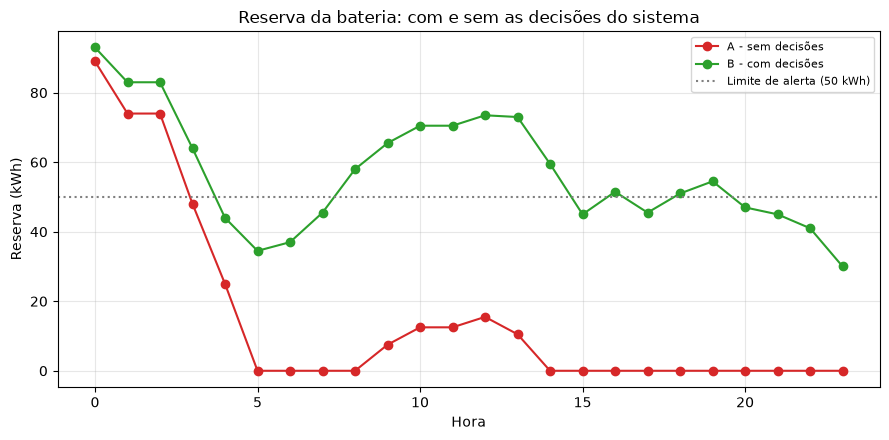

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(df_bateria["hora"], df_bateria["reserva_kwh"], marker="o",
        color="tab:red", label="A - sem decisões")
ax.plot(df_controle["hora"], df_controle["reserva_kwh"], marker="o",
        color="tab:green", label="B - com decisões")
ax.axhline(50, color="gray", linestyle=":", label="Limite de alerta (50 kWh)")

ax.set_xlabel("Hora")
ax.set_ylabel("Reserva (kWh)")
ax.set_title("Reserva da bateria: com e sem as decisões do sistema")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Resumo dos resultados

In [21]:
horas_risco = int(df["situacao"].str.startswith("RISCO").sum())
horas_alerta = int(df_decisoes["decisao"].str.startswith("ALERTA").sum())
horas_sugestao = int(df_decisoes["decisao"].str.startswith("SUGESTÃO").sum())

print("RESUMO DA ANÁLISE - 24 h")
print("=" * 62)
print(f"Geração do dia:  {geracao_total:6.1f} kWh "
      f"(solar {sum(series['solar_kwh']):.1f} + eólica {sum(series['eolica_kwh']):.1f})")
print(f"Consumo do dia:  {consumo_total:6.1f} kWh")
print(f"Saldo do dia:    {saldo:+6.1f} kWh")
print(f"Horas em risco (consumo > geração): {horas_risco}")
print(f"Horas em alerta: {horas_alerta} | Horas com sugestão de armazenar: {horas_sugestao}")
print(f"Reserva mínima da bateria: {df_bateria['reserva_kwh'].min():.1f} kWh "
      f"(inicial {bateria['reserva_inicial_kwh']:.0f} kWh)")
print(f"Consumo não atendido: {df_bateria['deficit_nao_atendido_kwh'].sum():.1f} kWh")

print()
print("Cenário B - sistema reagindo (seção 4.2):")
print(f"Consumo reduzido para {df_controle['consumo_kwh'].sum():.1f} kWh "
      f"(-{economia:.1f} kWh, {100 * economia / consumo_total:.1f}%)")
print(f"Consumo não atendido: {df_controle['deficit_nao_atendido_kwh'].sum():.1f} kWh | "
      f"horas com bateria vazia: {int((df_controle['reserva_kwh'] == 0).sum())}")
print(f"Reserva final do dia: {df_controle['reserva_kwh'].iloc[-1]:.1f} kWh")

RESUMO DA ANÁLISE - 24 h
Geração do dia:   621.0 kWh (solar 146.0 + eólica 475.0)
Consumo do dia:   879.0 kWh
Saldo do dia:    -258.0 kWh
Horas em risco (consumo > geração): 19
Horas em alerta: 23 | Horas com sugestão de armazenar: 0
Reserva mínima da bateria: 0.0 kWh (inicial 100 kWh)
Consumo não atendido: 158.0 kWh

Cenário B - sistema reagindo (seção 4.2):
Consumo reduzido para 691.0 kWh (-188.0 kWh, 21.4%)
Consumo não atendido: 0.0 kWh | horas com bateria vazia: 0
Reserva final do dia: 30.0 kWh


### Leitura dos resultados

- **Geração**: a eólica responde por cerca de três quartos da energia do dia (475 de 621 kWh) e não depende do horário; a solar só produz entre as 6 h e as 18 h, com pico de 22 kWh ao meio-dia.
- **Consumo**: fica entre 30 e 47 kWh por hora e supera a geração em 19 das 24 horas. O dia fecha em déficit de 258 kWh.
- **Reserva**: com 100 kWh iniciais e déficit contínuo, a bateria se esgota por volta da hora 5 e fica vazia por 14 horas, deixando 158 kWh de consumo sem atendimento. É o risco operacional mais grave identificado.
- **Decisões**: aplicadas sobre o dia original, 23 das 24 horas terminam em alerta. Em malha fechada (seção 4.2), o modo economia reduz o consumo em 188 kWh (21,4%), zera o consumo não atendido e termina o dia com 30 kWh de reserva — é aqui que a lógica de decisão mostra valor.
- **Previsão**: a reta vento → eólica tem R² de 0,96 e estima 27,9 kWh para 11 m/s, coerente com o valor esperado no enunciado (≈27 kWh).

### O que o sistema entrega

| Critério de avaliação | Como foi atendido |
| --- | --- |
| Estruturação de dados | Hierarquia dos sistemas, registros chave-valor por hora e listas paralelas (seções 2.1 a 2.3) |
| Lógica de decisão | `decidir()` com condições simples, combinadas e prioridade entre essenciais e não essenciais, aplicada hora a hora e em malha fechada (seções 4 e 4.2) |
| Implementação em Python | Funções pequenas, sem dependência de bibliotecas avançadas nas regras e na regressão |
| Documentação e organização | Este notebook, com leitura dos resultados e o módulo `gerar_dados.py` como única fonte de dados |